<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [NOAA Buoys](https://github.com/Query-farm/vgi-buoys)

NOAA NDBC buoy stations, latest observations and recent station histories for marine analysis.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-buoys/blob/main/notebooks/02_latest_is_not_a_fresh_wave_measurement.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-buoys/blob/main/notebooks/README.md)

## A latest report can still be too old or lack a wave measurement

How many reports in NOAA's latest-observation file satisfy an explicit age limit **and** contain a measured wave height? A station's inclusion, its instrument flag, observation time and measurement availability answer different questions. Keep every row while making those distinctions in SQL.

**Unchanged official recordings.** This notebook uses a separately captured NOAA station directory and network-wide latest file from 14 November 2026 UTC. The real released worker parses the original XML/text. These are public source observations, not synthetic values. Two independently retrieved files are not an atomic snapshot. The manifest retains original URLs, exact UTC acquisition times and hashes.

### Choose how old an observation may be

`MAX_AGE_MIN` is **30** minutes by default; change it to **120** for the experiment. The reference clock is the latest file's recorded acquisition time, held fixed across reruns. Eligibility requires a nonnegative age no greater than the chosen limit. This is an analytical policy, not a navigation or weather-safety rule. Missing timestamps, future timestamps and missing wave heights remain explicit cases.

In [1]:
MAX_AGE_MIN = 30  # Experiment: 120 minutes

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.34":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.34"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the session after updating the example tools, then run all.")

In [3]:
from vgi_notebooks import check_runtime, connect, finish, prepare, prose, theme

check_runtime()
prepare("buoys")
import matplotlib.pyplot as plt  # noqa: E402
from IPython.display import display  # noqa: E402

theme()

from buoys_example import cleanup, configure_latest  # noqa: E402

replay, previous_env, captured_at = configure_latest(MAX_AGE_MIN)
session = connect(globals())
SOURCE = f"NOAA NDBC · unchanged latest-file recording · acquired {captured_at[:19]} UTC"

### Connect the native worker release

The shared setup fetches verified companion recordings and selects their loopback server. Haybarn starts the public native release through the visible `github-auto` location. The notebook needs no Bun installation or worker source checkout.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
INSTALL icu;
LOAD icu;
SET TimeZone='UTC';
ATTACH 'buoys' (TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-buoys@v0.1.0');

,Success


### Materialize the two independent responses once

`latest_observations()` retrieves the entire latest file; its optional station filter would run after that download. `stations` is the named directory table, an alternative access form for the `stations()` function in the first notebook. The local `measurements` reference supplies explicit wave units. Materialization prevents repeated API requests during plotting and inspection.

In [5]:
%%sql
CREATE TABLE latest AS SELECT * FROM buoys.main.latest_observations();
CREATE TABLE directory AS SELECT * FROM buoys.main.stations;
CREATE TABLE units AS SELECT * FROM buoys.main.measurements;
CREATE TABLE aged AS
SELECT o.*, s.name, s.has_met, s.station_type,
       s.station_id IS NOT NULL AS in_directory,
       epoch(TIMESTAMPTZ '{{captured_at}}' - o.time)/60.0 AS age_minutes
FROM latest o LEFT JOIN directory s USING(station_id);
CREATE TABLE classified AS SELECT *,
 CASE WHEN time IS NULL THEN 'No timestamp'
      WHEN age_minutes < 0 THEN 'Future timestamp'
      WHEN age_minutes > {{MAX_AGE_MIN}} THEN 'Outside age limit'
      WHEN wave_height_m IS NULL THEN 'Within age / wave missing'
      ELSE 'Within age / wave measured' END AS report_class
FROM aged;

,Count


In [6]:
%%sql quality <<
SELECT (SELECT md5(string_agg(to_json(x)::VARCHAR, chr(59) ORDER BY station_id)) FROM (SELECT * EXCLUDE(source_url,fetched_at) FROM latest) x) AS source_fingerprint,
 count(*) AS report_rows, count(DISTINCT station_id) AS distinct_stations,
 count(*) FILTER (WHERE NOT in_directory) AS not_in_directory,
 count(*) FILTER (WHERE has_met IS NULL) AS unknown_met_flag,
 count(*) FILTER (WHERE time IS NULL) AS missing_times,
 count(wave_height_m) AS measured_wave_rows,
 count(*) FILTER (WHERE wave_height_m=0) AS measured_zeroes,
 min(time) AS oldest_observation, max(time) AS newest_observation
FROM classified;

In [7]:
display(quality)
q = quality.iloc[0]
assert q.report_rows > 0 and q.report_rows == q.distinct_stations
prose(
    f"The file contains **{int(q.report_rows):,} station reports**; **{int(q.measured_wave_rows):,}** include wave heights and **{int(q.measured_zeroes)}** are measured zeroes. **{int(q.not_in_directory)}** do not match the independently captured directory. Directory absence and a missing instrument flag do not erase a returned observation. The station-by-time key is checked before classification."
)

,source_fingerprint,report_rows,distinct_stations,not_in_directory,unknown_met_flag,missing_times,measured_wave_rows,measured_zeroes,oldest_observation,newest_observation
0,4171da09d57eb89c228c42cf77992302,834,834,0,0,0,174,0,2026-11-14 15:15:00-05:00,2026-11-14 18:05:00-05:00


The file contains **834 station reports**; **174** include wave heights and **0** are measured zeroes. **0** do not match the independently captured directory. Directory absence and a missing instrument flag do not erase a returned observation. The station-by-time key is checked before classification.

### Separate freshness from measured-wave availability

Every returned report belongs to exactly one category. Age-ineligible reports stay visible even if they contain wave data. A missing wave height within the age limit is not a zero. Relaxing the age limit can change eligibility; it cannot change the source values, their timestamps or the number of reports.

In [8]:
%%sql categories <<
WITH labels(label,sort_order) AS (VALUES
 ('Within age / wave measured',1),('Within age / wave missing',2),
 ('Outside age limit',3),('Future timestamp',4),('No timestamp',5))
SELECT l.label,l.sort_order,count(c.station_id) AS reports
FROM labels l LEFT JOIN classified c ON c.report_class=l.label
GROUP BY ALL ORDER BY l.sort_order;

,label,sort_order,reports
0,Within age / wave measured,1,70
1,Within age / wave missing,2,109
2,Outside age limit,3,655
3,Future timestamp,4,0
4,No timestamp,5,0


At **30 minutes**, **70 of 834 latest-file reports** are both age-eligible and measured for waves. Another **109** meet the age policy but have no wave measurement. This is a count of station reports, not ocean area, elapsed time or a random sample of sea conditions.

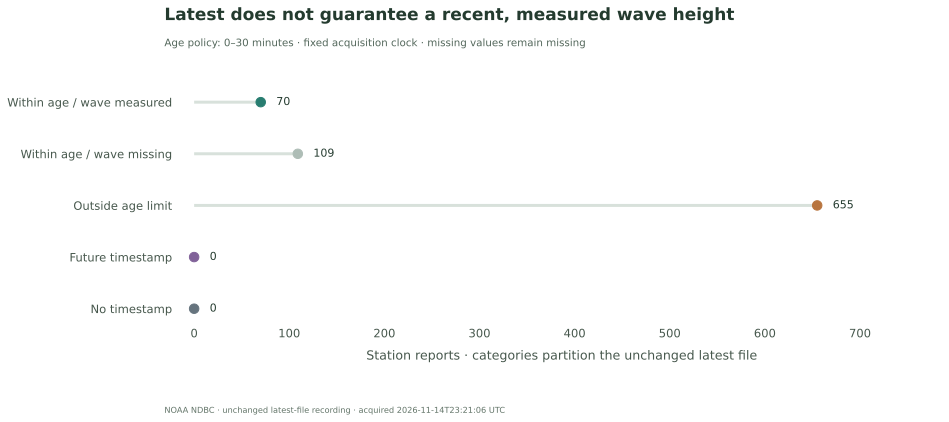

In [9]:
display(categories)
usable = int(categories.loc[categories.label.eq("Within age / wave measured"), "reports"].iloc[0])
missing = int(categories.loc[categories.label.eq("Within age / wave missing"), "reports"].iloc[0])
prose(
    f"At **{MAX_AGE_MIN} minutes**, **{usable:,} of {int(q.report_rows):,} latest-file reports** are both age-eligible and measured for waves. Another **{missing:,}** meet the age policy but have no wave measurement. This is a count of station reports, not ocean area, elapsed time or a random sample of sea conditions."
)
fig, ax = plt.subplots(figsize=(12, 6.2))
colors = ["#287D70", "#AEBDB6", "#B8753F", "#816299", "#66747E"]
y = list(range(len(categories)))
ax.hlines(y, 0, categories.reports, color="#D8E1DB", linewidth=3)
ax.scatter(categories.reports, y, color=colors, s=90, zorder=3)
for i, count in enumerate(categories.reports):
    ax.text(count + max(categories.reports.max() * 0.025, 1), i, f"{int(count):,}", va="center", fontsize=11)
ax.set(
    yticks=y,
    yticklabels=categories.label,
    xlabel="Station reports · categories partition the unchanged latest file",
    xlim=(-max(categories.reports.max() * 0.02, 1), max(categories.reports.max() * 1.20, 1)),
)
ax.invert_yaxis()
finish(
    fig,
    "Latest does not guarantee a recent, measured wave height",
    f"Age policy: 0–{MAX_AGE_MIN} minutes · fixed acquisition clock · missing values remain missing",
    SOURCE,
    name=f"latest-eligibility-{MAX_AGE_MIN}",
)

### Keep the selected measurements interpretable

Inspect the largest eligible measured wave heights alongside timestamps and ages. The reference-table join supplies units rather than guessing from a chart label. The output is a bounded display of the selected reports; its ordering is not a storm ranking, and a directory name does not validate the sensor reading.

In [10]:
%%sql sample <<
SELECT station_id,name,time,round(age_minutes,2) AS age_minutes,wave_height_m,
       u.output_unit,has_met,in_directory
FROM classified c CROSS JOIN units u
WHERE report_class='Within age / wave measured' AND u.column_name='wave_height_m'
ORDER BY wave_height_m DESC,station_id LIMIT 8;

In [11]:
display(sample)
prose(
    f"The display contains **{len(sample)}** of the **{usable}** eligible measured reports. Wave heights are in metres. Original observation timestamps determine eligibility; the replay-time fetched_at field does not. Expanding the age limit may change which station reports appear here."
)

,station_id,name,time,age_minutes,wave_height_m,output_unit,has_met,in_directory
0,46218,"Harvest, CA (071)",2026-11-14 17:56:00-05:00,25.11,8.4,m,True,True
1,46219,"San Nicolas Island, CA (067)",2026-11-14 17:56:00-05:00,25.11,7.8,m,True,True
2,46207,East Dellwood,2026-11-14 18:00:00-05:00,21.11,6.6,m,True,True
3,46229,"UMPQUA OFFSHORE, OR (139)",2026-11-14 17:56:00-05:00,25.11,6.6,m,True,True
4,46214,"Point Reyes, CA (029)",2026-11-14 17:56:00-05:00,25.11,6.4,m,True,True
5,46147,South Moresby,2026-11-14 18:00:00-05:00,21.11,6.0,m,True,True
6,46244,"Humboldt Bay, North Spit, CA (168)",2026-11-14 17:56:00-05:00,25.11,5.9,m,True,True
7,46132,South Brooks,2026-11-14 18:00:00-05:00,21.11,5.6,m,True,True


The display contains **8** of the **70** eligible measured reports. Wave heights are in metres. Original observation timestamps determine eligibility; the replay-time fetched_at field does not. Expanding the age limit may change which station reports appear here.

### Reconcile the complete file and the selection

Check the station key, category partition, wave units and fixed reference clock. These checks establish query relationships and preserve source missingness. They do not establish instrument health, perfect directory coverage or synchronized acquisition.

In [12]:
%%sql checks <<
SELECT 'unique station and observation key' AS check_name,count(*)=count(DISTINCT(station_id,time)) AS passed FROM latest
UNION ALL SELECT 'unique directory key',count(*)=count(DISTINCT station_id) FROM directory
UNION ALL SELECT 'left join preserves report count',(SELECT count(*) FROM classified)=(SELECT count(*) FROM latest)
UNION ALL SELECT 'five categories partition reports',bool_and(report_class IN ('No timestamp','Future timestamp','Outside age limit','Within age / wave missing','Within age / wave measured')) FROM classified
UNION ALL SELECT 'eligible measured values are present',count(*)=0 FROM classified WHERE report_class='Within age / wave measured' AND wave_height_m IS NULL
UNION ALL SELECT 'eligible ages inside policy',bool_and(age_minutes BETWEEN 0 AND {{MAX_AGE_MIN}}) FROM classified WHERE report_class LIKE 'Within age%'
UNION ALL SELECT 'missing-wave category preserves NULL',bool_and(wave_height_m IS NULL) FROM classified WHERE report_class='Within age / wave missing'
UNION ALL SELECT 'wave unit is metres without rescaling',count(*)=1 AND bool_and(source_unit='m' AND output_unit='m' AND scale=1) FROM units WHERE column_name='wave_height_m'
UNION ALL SELECT 'broader age limit cannot lose measured reports',count(*) FILTER (WHERE age_minutes BETWEEN 0 AND {{MAX_AGE_MIN}} AND wave_height_m IS NOT NULL)<=count(*) FILTER (WHERE age_minutes BETWEEN 0 AND 120 AND wave_height_m IS NOT NULL) FROM classified
ORDER BY check_name;

In [13]:
display(checks)
assert len(checks) == 9 and checks.passed.notna().all() and checks.passed.all()
assert int(categories.reports.sum()) == int(q.report_rows)
assert sorted(replay.requests) == ["/activestations.xml", "/data/latest_obs/latest_obs.txt"]
prose(
    "All nine SQL checks pass. Exactly one directory and one latest-file request were made; the units reference required no network call. The age-policy experiment reuses those identical response bytes."
)

,check_name,passed
0,broader age limit cannot lose measured reports,True
1,eligible ages inside policy,True
2,eligible measured values are present,True
3,five categories partition reports,True
4,left join preserves report count,True
5,missing-wave category preserves NULL,True
6,unique directory key,True
7,unique station and observation key,True
8,wave unit is metres without rescaling,True


All nine SQL checks pass. Exactly one directory and one latest-file request were made; the units reference required no network call. The age-policy experiment reuses those identical response bytes.

### Experiment: allow a two-hour-old report

Change **MAX_AGE_MIN from 30 to 120**, restart and run all. Predict that age-eligible measured reports cannot decrease, while the complete-file row count, measured-wave total, source timestamps and values remain fixed. Compare the category chart and bounded example rows. Reset to **30**.

The clock stays at the recorded acquisition time, even if you run this notebook months later. The older wave-exceedance notebook uses its own earlier capture/window; these two recordings must not be treated as a synchronized cross-file join.

In [14]:
session.close()
cleanup(replay, previous_env)

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-buoys](https://github.com/Query-farm/vgi-buoys)